In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/Users/melanierea/Downloads/LTOTALNSA.csv")
df.head()

,observation_date,LTOTALNSA
0,1976-01-01,864.6
1,1976-02-01,973.3
2,1976-03-01,1216.1
3,1976-04-01,1163.2
4,1976-05-01,1176.1


In [26]:
df = pd.read_csv("/Users/melanierea/Downloads/LTOTALNSA.csv")
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.set_index("observation_date")
df.index.name = "date"
df = df.rename(columns={"LTOTALNSA": "sales"})

sales = df["sales"]
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 609 entries, 1976-01-01 to 2026-09-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sales   609 non-null    float64
dtypes: float64(1)
memory usage: 9.5 KB


In [27]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 609 entries, 1976-01-01 to 2026-09-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sales   609 non-null    float64
dtypes: float64(1)
memory usage: 9.5 KB


In [28]:
print(sales["2019"].head())
print(sales["2019-03":"2019-09"])
print(sales.index.day_name()[:5])

date
2019-01-01    1133.666
2019-02-01    1252.156
2019-03-01    1599.488
2019-04-01    1327.238
2019-05-01    1582.162
Name: sales, dtype: float64
date
2019-03-01    1599.488
2019-04-01    1327.238
2019-05-01    1582.162
2019-06-01    1510.420
2019-07-01    1397.004
2019-08-01    1639.332
2019-09-01    1267.674
Name: sales, dtype: float64
Index(['Thursday', 'Sunday', 'Monday', 'Thursday', 'Saturday'], dtype='str', name='date')


In [29]:
print(pd.date_range("2024-01-01", periods=5, freq="D"))
print(pd.date_range("2024-01-01", periods=5, freq="W"))
print(pd.date_range("2024-01-01", periods=5, freq="ME"))
print(pd.date_range("2024-01-01", periods=5, freq="MS"))
print(pd.date_range("2024-01-01", periods=4, freq="QE"))

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05'],
              dtype='datetime64[us]', freq='D')
DatetimeIndex(['2024-01-07', '2024-01-14', '2024-01-21', '2024-01-28',
               '2024-02-04'],
              dtype='datetime64[us]', freq='W-SUN')
DatetimeIndex(['2024-01-31', '2024-02-29', '2024-03-31', '2024-04-30',
               '2024-05-31'],
              dtype='datetime64[us]', freq='ME')
DatetimeIndex(['2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01',
               '2024-05-01'],
              dtype='datetime64[us]', freq='MS')
DatetimeIndex(['2024-03-31', '2024-06-30', '2024-09-30', '2024-12-31'], dtype='datetime64[us]', freq='QE-DEC')


In [30]:
full = pd.date_range(sales.index.min(), sales.index.max(), freq="MS")
print("Missing months:", full.difference(sales.index))
print("Expected:", len(full), "Actual:", len(sales))
print("Sorted:", sales.index.is_monotonic_increasing)

Missing months: DatetimeIndex([], dtype='datetime64[us]', freq='MS')
Expected: 609 Actual: 609
Sorted: True


In [31]:
quarterly = sales.resample("QE").sum()
yearly = sales.resample("YE").sum()
print(quarterly.tail())
print(yearly.tail())

date
2025-09-30    4121.816
2025-12-31    4026.067
2026-03-31    3667.014
2026-06-30    4260.694
2026-09-30    4066.038
Freq: QE-DEC, Name: sales, dtype: float64
date
2022-12-31    13754.339
2023-12-31    15502.479
2024-12-31    15851.418
2025-12-31    16259.249
2026-12-31    11993.746
Freq: YE-DEC, Name: sales, dtype: float64


In [32]:
idx = pd.date_range("2024-01-01", "2024-03-31", freq="D")
daily = pd.Series(np.random.randint(100, 200, size=len(idx)), index=idx)
print(daily.resample("ME").sum())

2024-01-31    4623
2024-02-29    4153
2024-03-31    4622
Freq: ME, dtype: int64


In [33]:
compare = pd.DataFrame({
    "sales": sales,
    "prev_month": sales.shift(1),
    "diff": sales.diff(),
})
print(compare.head())

             sales  prev_month   diff
date                                 
1976-01-01   864.6         NaN    NaN
1976-02-01   973.3       864.6  108.7
1976-03-01  1216.1       973.3  242.8
1976-04-01  1163.2      1216.1  -52.9
1976-05-01  1176.1      1163.2   12.9


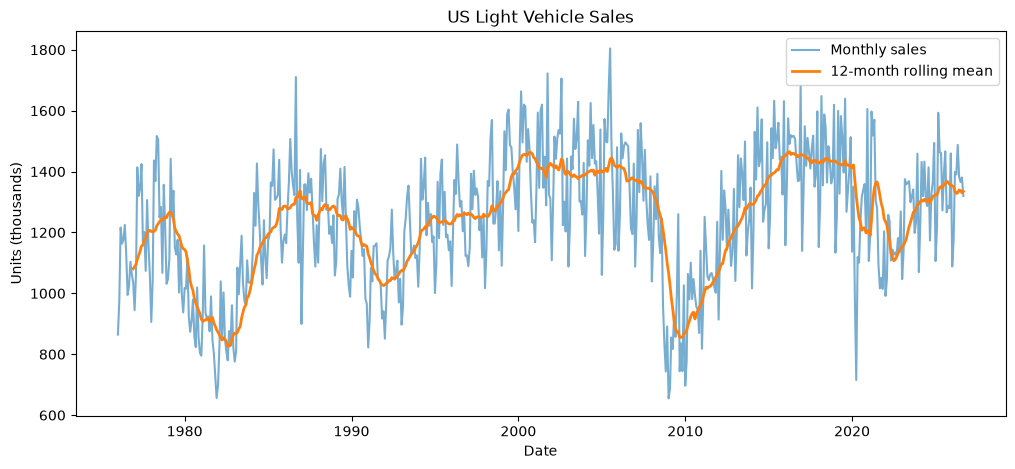

In [34]:
rolling = sales.rolling(window=12).mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sales.index, sales, label="Monthly sales", alpha=0.6)
ax.plot(rolling.index, rolling, label="12-month rolling mean", linewidth=2)
ax.set_title("US Light Vehicle Sales")
ax.set_xlabel("Date")
ax.set_ylabel("Units (thousands)")
ax.legend()
plt.show()

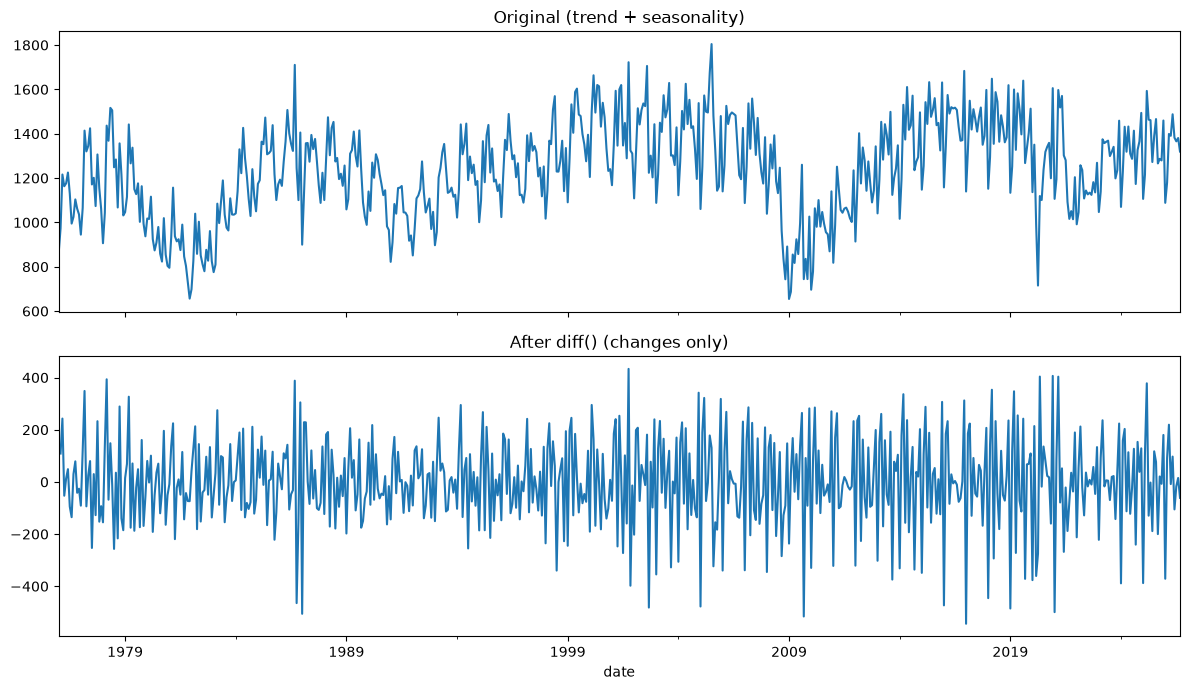

In [35]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sales.plot(ax=axes[0], title="Original (trend + seasonality)")
sales.diff().plot(ax=axes[1], title="After diff() (changes only)")
plt.tight_layout()
plt.show()

In [38]:
monthly = sales.resample("ME").sum()
quarterly = sales.resample("QE").sum()
print(monthly.head())
print(quarterly.head())


date
1976-01-31     864.6
1976-02-29     973.3
1976-03-31    1216.1
1976-04-30    1163.2
1976-05-31    1176.1
Freq: ME, Name: sales, dtype: float64
date
1976-03-31    3054.0
1976-06-30    3564.2
1976-09-30    3149.9
1976-12-31    3201.7
1977-03-31    3424.4
Freq: QE-DEC, Name: sales, dtype: float64
